In [132]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
from scipy.sparse import issparse
from scipy.stats import mannwhitneyu
import scanpy as sc
import tqdm
import functools
import glob
import gzip as gz
import itertools
import math
import os
import sys
from importlib import reload

sys.path.append('/Genomics/pritykinlab/dillon/perturbseq/scripts/utils')
import misc
import figure_format
reload(figure_format)
from figure_format import get_adata
from figure_format import cell_type_colors
from figure_format import perturbation_colors
from figure_format import cell_type_orders_gene10
from figure_format import cell_type_orders_trim28_setdb1
from figure_format import cell_type_orders_multiome
from figure_format import perturbation_orders_gene10
from figure_format import dotplot_genes
from figure_format import condition_colors_dict
from GO import GOParser


In [133]:
plt.rcParams["axes.titlesize"] = 25
plt.rcParams["axes.labelsize"] = 25
plt.rcParams["xtick.labelsize"] = 20
plt.rcParams["ytick.labelsize"] = 20
plt.rcParams["lines.markersize"] = 5
plt.rcParams['axes.grid'] = False
plt.rcParams['xtick.bottom'] = True
plt.rcParams['ytick.left'] = True
plt.rcParams['xtick.major.size'] = 5
plt.rcParams['xtick.minor.size'] = 3
plt.rcParams['ytick.major.size'] = 5
plt.rcParams['ytick.minor.size'] = 3
plt.rcParams['axes.labelcolor'] = 'black'
plt.rcParams['axes.edgecolor'] = 'black'
plt.rcParams['xtick.color'] = 'black'
plt.rcParams['legend.fontsize'] = 15
plt.rcParams['legend.title_fontsize'] = 15
plt.rcParams['legend.edgecolor'] = 'dimgray'
plt.rcParams['figure.figsize'] = (7,7)

In [134]:
trim28_setdb1_adata = get_adata('trim28_setdb1', use_cells_only_one_construct=False, remove_NG=False, get_raw_scaled=True)
gene10_adata = get_adata('gene_10', use_cells_only_one_construct=False, remove_NG=False, get_raw_scaled=True)

In [135]:
sc.tl.leiden(gene10_adata, resolution=3)

In [136]:
trim28_setdb1_adata.obs['leiden'] = trim28_setdb1_adata.obs['leiden_3']

# Early Activation

/Genomics/pritykinlab/dillon/software/miniconda/envs/envs/scvi3/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/Genomics/pritykinlab/dillon/software/miniconda/envs/envs/scvi3/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


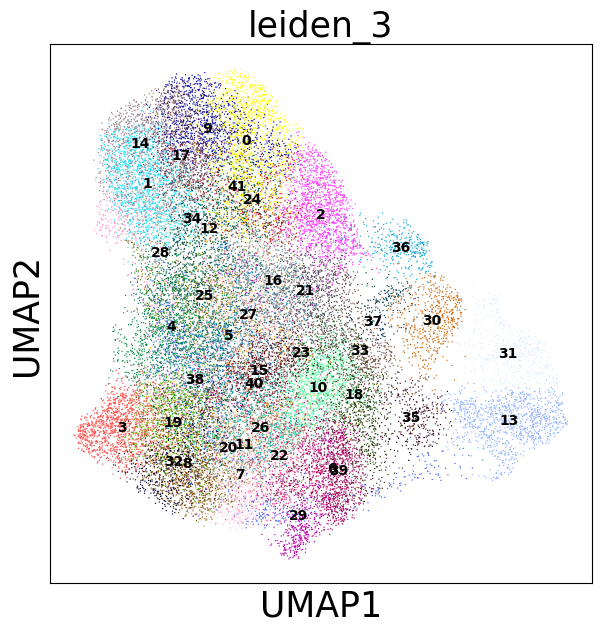

In [30]:
sc.pl.umap(trim28_setdb1_adata, color='leiden_3', legend_loc='on data')

/Genomics/pritykinlab/dillon/software/miniconda/envs/envs/scvi3/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/Genomics/pritykinlab/dillon/software/miniconda/envs/envs/scvi3/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/Genomics/pritykinlab/dillon/software/miniconda/envs/envs/scvi3/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action t

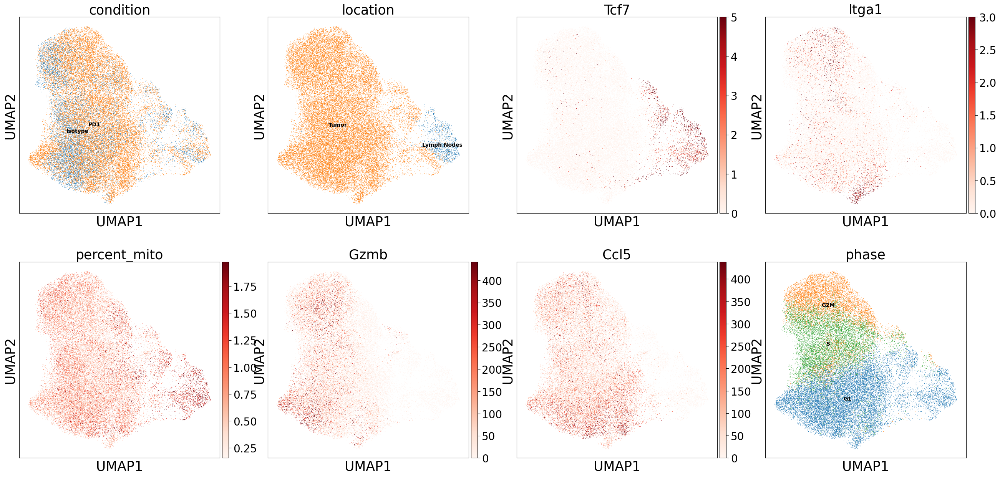

In [41]:
sc.pl.umap(adata, color=['condition', 'location', 'Tcf7', 'Itga1', 'percent_mito', 'Gzmb', 'Ccl5', 'phase'],
           legend_loc='on data', cmap='Reds', vmin="p2", vmax="p98")

/Genomics/pritykinlab/dillon/software/miniconda/envs/envs/scvi3/lib/python3.11/site-packages/scanpy/plotting/_dotplot.py:168: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  obs_bool.groupby(level=0).sum() / obs_bool.groupby(level=0).count()
/Genomics/pritykinlab/dillon/software/miniconda/envs/envs/scvi3/lib/python3.11/site-packages/scanpy/plotting/_dotplot.py:178: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  dot_color_df = self.obs_tidy.groupby(level=0).mean()
/Genomics/pritykinlab/dillon/software/miniconda/envs/envs/scvi3/lib/python3.11/site-packages/scanpy/tools/_dendrogram.py:135: FutureWarning: The defaul

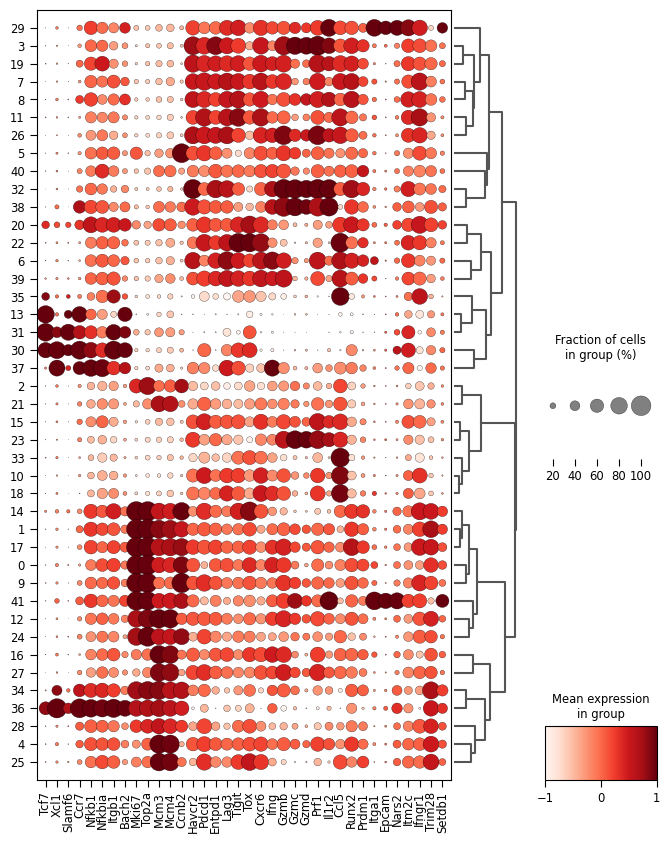

In [40]:
import matplotlib as mpl
sc.pl.dotplot(trim28_setdb1_adata, groupby = "leiden_3", cmap = "Reds",
              norm = mpl.colors.Normalize(vmin=-1, vmax=1),
              var_names = dotplot_genes,
              layer='norm_log_zscore',
              dendrogram=True,
              figsize=(8, 10))

In [47]:
multiome_rna_adata = get_adata('multiome_rna')

In [48]:
import DE_testing

,Gene,Log2FC,rank_sum_statistic,P-value,Adjusted P-value
0,Xkr4,0.232175,-0.020642,0.983531,0.999663
1,Mrpl15,-0.372920,-4.136480,0.000035,0.000858
2,Lypla1,0.478486,0.154426,0.877274,0.999663
3,Tcea1,0.216249,-1.366016,0.171934,0.546543
4,Rgs20,0.141116,0.096812,0.922875,0.999663


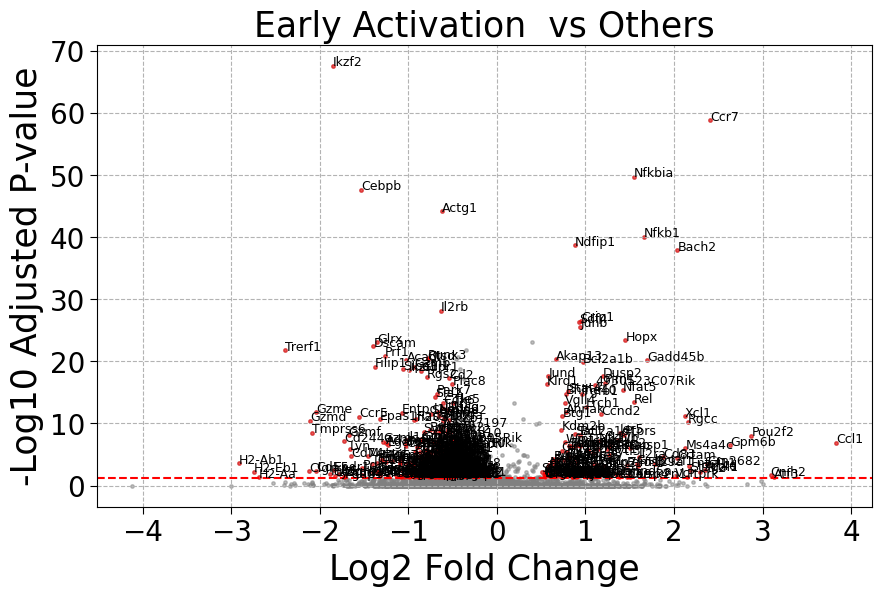

In [49]:
# Perform DE Testing: Early Activation vs. Others in multiome_rna_adata
early_activation_cells = multiome_rna_adata.obs_names[multiome_rna_adata.obs['cell_type'] == 'Early Activation'].tolist()
other_cells = multiome_rna_adata.obs_names[multiome_rna_adata.obs['cell_type'] != 'Early Activation'].tolist()

results_early_activation_DE = DE_testing.wilcoxon_DE_test(
    multiome_rna_adata,
    early_activation_cells,
    other_cells,
    norm_layer='norm'
)

# Display results
display(results_early_activation_DE.head())

# Volcano plot
DE_testing.volcano_plot(
    results_early_activation_DE,
    'Early Activation  vs Others'
)

In [65]:
early_activation_signature = results_early_activation_DE.query('`Adjusted P-value` < 0.05 and Log2FC > 0.5')['Gene'].tolist()
print(f"Early activation signature ({len(early_activation_signature)} genes):")
print(early_activation_signature)

Early activation signature (127 genes):
['Il18r1', 'Il18rap', 'Stat4', 'Cd28', 'Fam129a', 'Ier5', '4930523C07Rik', 'Xcl1', 'Itpkb', 'Atf3', 'Il2ra', 'Fnbp1', 'Traf1', 'Zeb2', 'Pkp4', 'Wipf1', 'Cd82', 'Cd44', 'Dusp2', 'Bcl2l1', 'Nfkb1', 'Bach2', 'Jun', 'Pde4b', 'Ece1', 'Camk2n1', 'Sdf4', 'Arap2', 'Fryl', 'Hopx', 'Igfbp7', 'Lrrc8d', 'Kdm2b', 'Orai1', 'Mdfic', 'Tes', 'Slc6a6', 'Foxp1', 'Bhlhe40', 'Vgll4', 'Lag3', 'Ccnd2', 'Cd69', 'Klrd1', 'Dusp16', 'Fosb', 'Pou2f2', 'Tgfb1', 'Nfkbib', 'Akap13', 'Dennd5a', 'Dusp4', 'Jund', 'Adgre5', 'Junb', 'Nfat5', 'Itgb1', 'Nrgn', 'Crtam', 'Ubash3b', 'Gm20275', 'Rora', 'Bcl2a1d', 'Bcl2a1b', 'Plscr1', 'Mapkapk3', 'Cish', 'Utrn', 'Stx11', 'Tnfaip3', 'Ptprk', 'Gadd45b', 'Btg1', 'Rel', 'Stk10', 'Sqstm1', 'Kdm6b', 'Ccl1', 'Slfn2', 'Msi2', 'Spag9', 'Skap1', 'Ccr7', 'Arl4d', 'Rnf157', 'Ubald2', 'Baz1a', 'Nfkbia', 'Gm15283', 'Hif1a', 'Foxn3', 'Crip1', 'Klf6', 'Serpinb6b', 'Cd83', 'Adamts6', 'Plk2', 'Vcl', 'Arf4', 'Glud1', 'Lgals3', 'Lrch1', 'Tnfsf11', 'Rgcc', 'I

In [66]:
misc.my_score_genes(trim28_setdb1_adata, early_activation_signature, 'early_activation_score')
misc.my_score_genes(gene10_adata, early_activation_signature, 'early_activation_score')
misc.my_score_genes(multiome_rna_adata, early_activation_signature, 'early_activation_score')

In [131]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scanpy as sc
import matplotlib as mpl

def comprehensive_activation_plot(
    adata,
    dataset_name,
    dotplot_genes,
    signature_genes,
    score_key='activation_score',
    cluster_key='leiden',
    cmap_activation='Reds',
    cmap_clusters='tab20'
):
    """
    General comprehensive plotting function for gene signature scores.
    """
    # Score cells using signature genes
    import misc
    misc.my_score_genes(adata, signature_genes, score_key)

    # Compute median activation scores and explicitly reorder clusters
    cluster_medians = adata.obs.groupby(cluster_key)[score_key].median().sort_values(ascending=False)
    sorted_clusters = cluster_medians.index.tolist()

    # Explicit mapping old labels → new labels
    label_mapping = {old_label: str(new_label) for new_label, old_label in enumerate(sorted_clusters)}

    # Save reordered labels explicitly
    new_cluster_key = f"{cluster_key}_reordered_{score_key}"
    adata.obs[new_cluster_key] = adata.obs[cluster_key].map(label_mapping)

    # Ensure correct sorting order clearly
    cluster_order = [str(i) for i in range(len(sorted_clusters))]

    # === 1. UMAP colored by activation scores explicitly ===
    sc.pl.umap(
        adata,
        color=score_key,
        cmap=cmap_activation,
        vmax='p99',
        title=f'{dataset_name}: UMAP by {score_key}',
        frameon=False,
        show=True
    )

    # === 2. UMAP colored by reordered clusters explicitly ===
    sc.pl.umap(
        adata,
        color=new_cluster_key,
        palette=cmap_clusters,
        legend_loc='on data',
        title=f'{dataset_name}: UMAP by reordered {cluster_key}',
        frameon=False,
        show=True
    )

    # === 3. Sorted Boxplot of activation scores clearly ===
    plt.figure(figsize=(10,7))
    sns.boxplot(
        data=adata.obs,
        x=new_cluster_key,
        y=score_key,
        order=cluster_order,
        whis=np.inf,
        color='white',
        fliersize=0,
        width=0.5
    )

    plt.title(f'{dataset_name}: {score_key} by reordered {cluster_key}', fontsize=18)
    plt.xlabel(f'Reordered {cluster_key.capitalize()} Cluster', fontsize=16)
    plt.ylabel(score_key.replace('_', ' ').capitalize(), fontsize=16)
    plt.xticks(rotation=45)
    sns.despine()
    plt.tight_layout()
    plt.show()

    # === 4. Dotplot explicitly ordered by reordered cluster labels, top 7 clusters ONLY ===
    top7_clusters = cluster_order[:7]  # Top 7 clusters explicitly
    sc.pl.dotplot(
        adata[adata.obs[new_cluster_key].isin(top7_clusters)],
        groupby=new_cluster_key,
        var_names=dotplot_genes,
        cmap="Reds",
        norm=mpl.colors.Normalize(vmin=-1, vmax=1),
        layer='norm_log_zscore',
        categories_order=top7_clusters,
        figsize=(8, 2),
        title=f'{dataset_name}: Gene Expression Dotplot (Top 7 Clusters)'
    )

/tmp/ipykernel_2760416/3580382618.py:25: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cluster_medians = adata.obs.groupby(cluster_key)[score_key].median().sort_values(ascending=False)


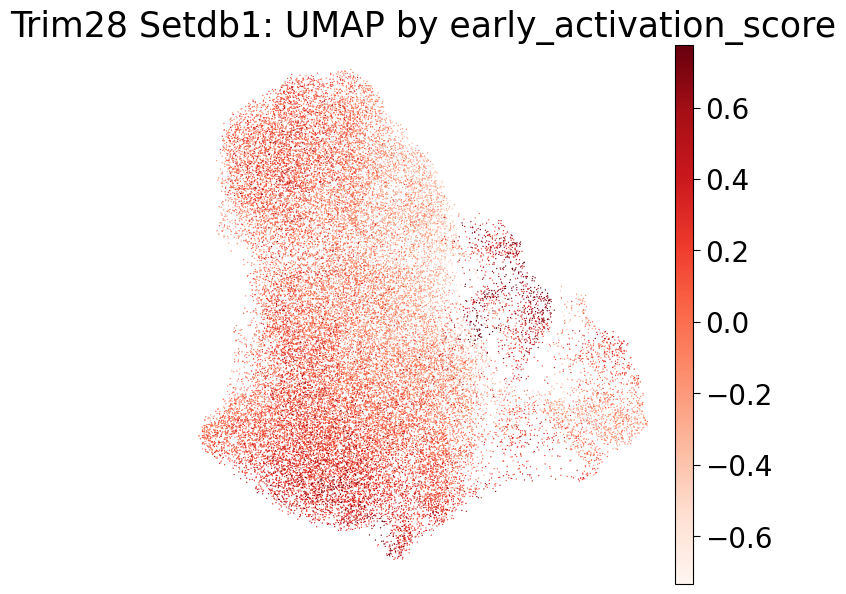

/Genomics/pritykinlab/dillon/software/miniconda/envs/envs/scvi3/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/Genomics/pritykinlab/dillon/software/miniconda/envs/envs/scvi3/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


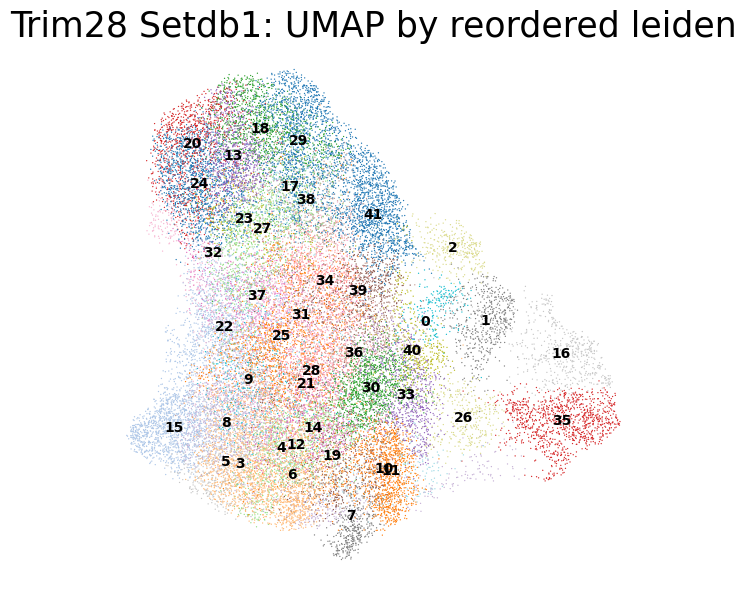

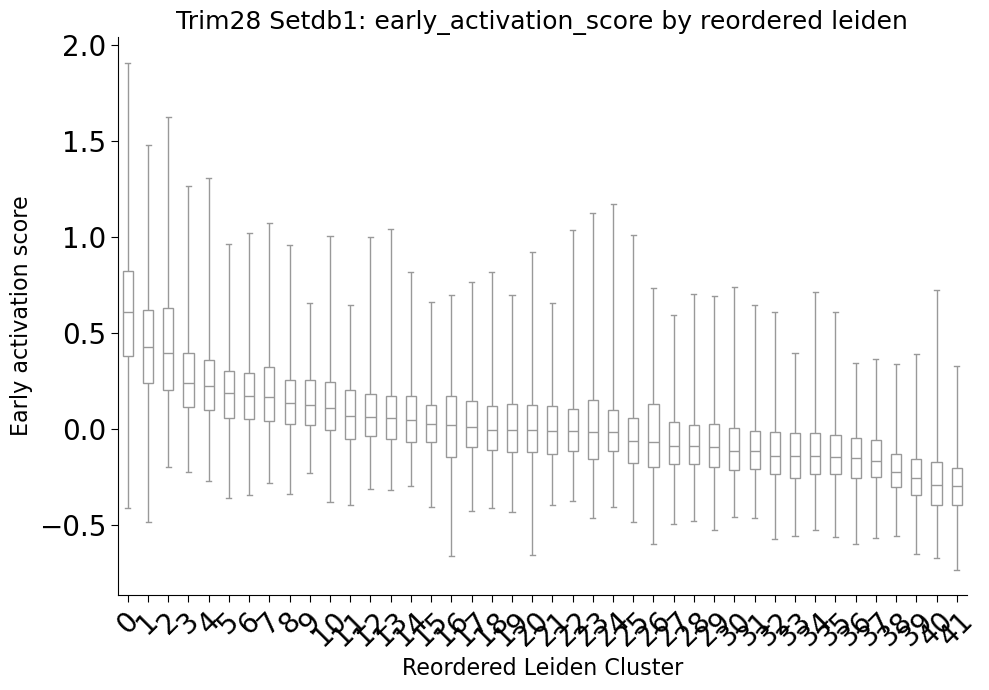

/Genomics/pritykinlab/dillon/software/miniconda/envs/envs/scvi3/lib/python3.11/site-packages/scanpy/plotting/_dotplot.py:168: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  obs_bool.groupby(level=0).sum() / obs_bool.groupby(level=0).count()
/Genomics/pritykinlab/dillon/software/miniconda/envs/envs/scvi3/lib/python3.11/site-packages/scanpy/plotting/_dotplot.py:178: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  dot_color_df = self.obs_tidy.groupby(level=0).mean()
/Genomics/pritykinlab/dillon/software/miniconda/envs/envs/scvi3/lib/python3.11/site-packages/scanpy/plotting/_dotplot.py:747: UserWarning: No data for 

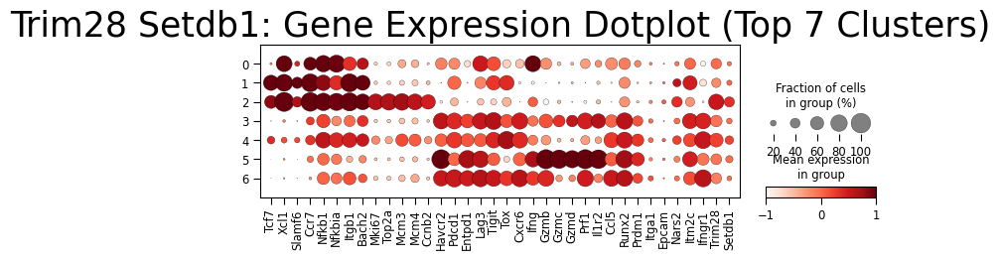

/tmp/ipykernel_2760416/3580382618.py:25: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cluster_medians = adata.obs.groupby(cluster_key)[score_key].median().sort_values(ascending=False)


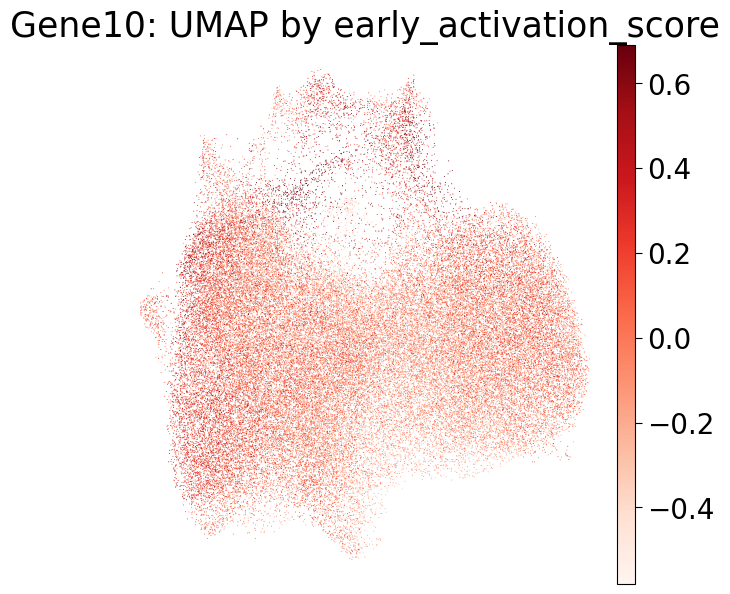

/Genomics/pritykinlab/dillon/software/miniconda/envs/envs/scvi3/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/Genomics/pritykinlab/dillon/software/miniconda/envs/envs/scvi3/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


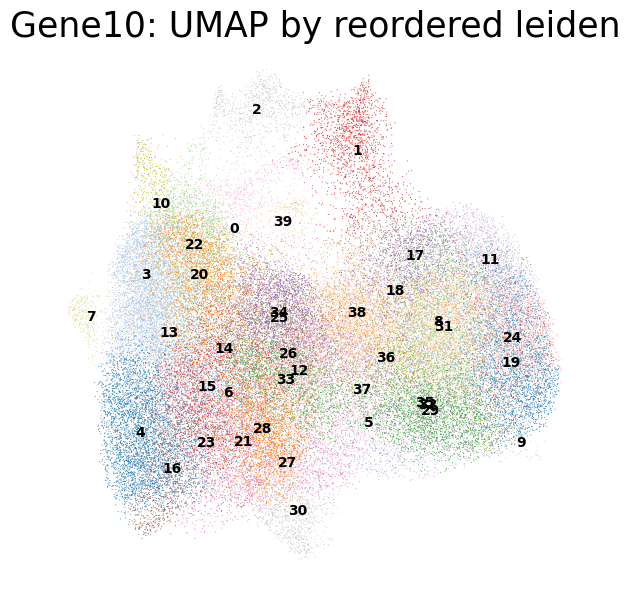

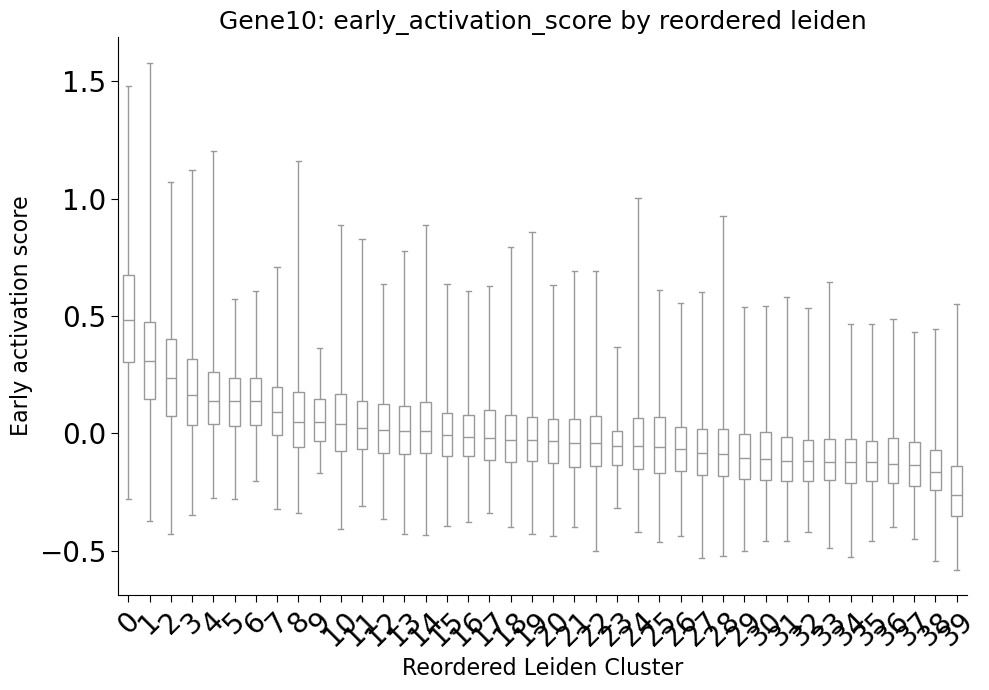

/Genomics/pritykinlab/dillon/software/miniconda/envs/envs/scvi3/lib/python3.11/site-packages/scanpy/plotting/_dotplot.py:168: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  obs_bool.groupby(level=0).sum() / obs_bool.groupby(level=0).count()
/Genomics/pritykinlab/dillon/software/miniconda/envs/envs/scvi3/lib/python3.11/site-packages/scanpy/plotting/_dotplot.py:178: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  dot_color_df = self.obs_tidy.groupby(level=0).mean()
/Genomics/pritykinlab/dillon/software/miniconda/envs/envs/scvi3/lib/python3.11/site-packages/scanpy/plotting/_dotplot.py:747: UserWarning: No data for 

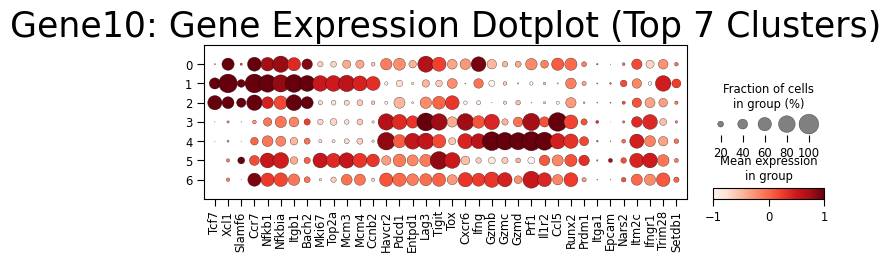

In [137]:
trim28_setdb1_adata = get_adata('trim28_setdb1', use_cells_only_one_construct=False, remove_NG=False, get_raw_scaled=True)
gene10_adata = get_adata('gene_10', use_cells_only_one_construct=False, remove_NG=False, get_raw_scaled=True)
sc.tl.leiden(gene10_adata, resolution=3)
trim28_setdb1_adata.obs['leiden'] = trim28_setdb1_adata.obs['leiden_3']

# For Early Activation:
comprehensive_activation_plot(
    trim28_setdb1_adata,
    dataset_name='Trim28 Setdb1',
    dotplot_genes=dotplot_genes,
    signature_genes=early_activation_signature,
    score_key='early_activation_score'
)

comprehensive_activation_plot(
    gene10_adata,
    dataset_name='Gene10',
    dotplot_genes=dotplot_genes,
    signature_genes=early_activation_signature,
    score_key='early_activation_score'
)

## Get a Granzyme and Ccl5+ signature

In [116]:
trim28_setdb1_adata = get_adata('trim28_setdb1', use_cells_only_one_construct=False, remove_NG=False, remove_lymph_node=True)
gene10_adata = get_adata('gene_10', use_cells_only_one_construct=False, remove_NG=False)

In [118]:
import DE_testing
from importlib import reload
reload(DE_testing)

def run_custom_de_tests(adata, celltype, dataset_label):
    group1 = adata.obs_names[adata.obs['cell_type'] == celltype]
    group2 = adata.obs_names[adata.obs['cell_type'] != celltype]
    
    results_df = DE_testing.wilcoxon_DE_test(adata, group1, group2)
    
    # Volcano plot
#     DE_testing.volcano_plot(results_df, f"{celltype} vs Others - {dataset_label}", logFC_label_threshold=1.0)
    
    return results_df

# Run DE for Granzyme High cells
gh_trim28_setdb1 = run_custom_de_tests(trim28_setdb1_adata, 'Granzyme High', 'Trim28-Setdb1')
gh_gene10 = run_custom_de_tests(gene10_adata, 'Granzyme High', 'Gene10')

# Run DE for Ccl5+ cells
ccl5_trim28_setdb1 = run_custom_de_tests(trim28_setdb1_adata, 'Ccl5+', 'Trim28-Setdb1')
ccl5_gene10 = run_custom_de_tests(gene10_adata, 'Ccl5+', 'Gene10')

In [140]:
def get_signature_genes(df1, df2, logfc_thresh=1.0, sig_thresh=0.05):
    # Ensure both dataframes are indexed by Gene
    df1 = df1.set_index('Gene')
    df2 = df2.set_index('Gene')

    # Find common genes
    common_genes = df1.index.intersection(df2.index)

    # Keep only genes significant in both datasets and with logFC ≥ threshold
    signature_genes = [
        gene for gene in common_genes
        if (df1.loc[gene, 'Log2FC'] >= logfc_thresh and df2.loc[gene, 'Log2FC'] >= logfc_thresh)
        and (df1.loc[gene, 'Adjusted P-value'] <= sig_thresh and df2.loc[gene, 'Adjusted P-value'] <= sig_thresh)
    ]

    return signature_genes

# Granzyme High signature genes (both significant and logFC ≥ 1)
gh_signature_genes = get_signature_genes(
    gh_trim28_setdb1, 
    gh_gene10, 
    logfc_thresh=1.0, 
    sig_thresh=0.05
)

# Ccl5+ signature genes (both significant and logFC ≥ 1)
ccl5_signature_genes = get_signature_genes(
    ccl5_trim28_setdb1, 
    ccl5_gene10, 
    logfc_thresh=1.0, 
    sig_thresh=0.05
)

# Clearly print the updated signatures:
print(f"Granzyme High Signature Genes ({len(gh_signature_genes)} genes):")
print(gh_signature_genes)

print(f"\nCcl5+ Signature Genes ({len(ccl5_signature_genes)} genes):")
print(ccl5_signature_genes)

Granzyme High Signature Genes (102 genes):
['Il1r2', 'Mreg', 'Serpine2', 'Lamc2', 'Dnm3', 'Fcrl6', 'Spta1', 'Il2ra', 'Nebl', 'Cd59b', 'Cd59a', 'D430041D05Rik', 'Spint1', 'AA467197', 'Mall', 'Smox', 'Sdc4', 'Slc13a3', 'Mgarp', 'S100a1', 'Gstm5', 'Gipc2', 'Penk', 'Cdh17', 'Unc13b', 'Rusc2', 'Cdkn2b', 'Trp73', 'Kctd8', 'Kit', 'Albfm1', 'Spp1', '2210408F21Rik', 'Akr1b8', 'Tmem150a', 'Gm44040', 'Plxnd1', '1700030F04Rik', 'Slc2a3', 'Dmwd', 'Ceacam1', 'Zbtb32', 'Scn1b', 'Il4i1', 'Ntf5', 'Kctd14', 'Stard10', 'Bnip3', 'Adam8', 'Ppp1r3b', 'Dixdc1', 'C430002N11Rik', 'Rab6b', 'Ccr1', 'Oit3', 'Prf1', 'Gm867', 'Gm10941', 'Ckap4', 'Tcn2', 'Gas2l1', 'Upp1', 'Adora2b', 'Kctd11', 'Aldoc', 'Copz2', 'Itgb3', 'Serpinb9b', 'Pxdc1', 'Gm33424', 'Ltb4r1', 'Mcpt8', 'Gzme', 'Gzmd', 'Gzmg', 'Gm4022', 'Gzmf', 'Gzmc', 'Gzmb', 'Neil2', 'Basp1', 'Ndrg1', 'Kdelr3', 'Mgat3', 'Cntn1', 'Ccdc184', 'Tm4sf19', 'Jam2', 'Bace2', 'Cdkn1a', 'Tff1', 'Cd70', 'Emilin2', 'Epas1', 'Dsc2', 'Cystm1', 'Cd14', 'Ltbp3', 'Spin4', 'Rnf128'

In [128]:
import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import pearsonr, spearmanr

def scatterplot_with_labels(df_x, df_y, xlabel, ylabel, title, sig_thresh=0.05, logFC_thresh=1.0):
    # Set index as Gene for easier access
    df_x = df_x.set_index('Gene')
    df_y = df_y.set_index('Gene')

    # Common genes
    common_genes = df_x.index.intersection(df_y.index)

    # Create plotting dataframe
    plot_df = pd.DataFrame({
        'Gene': common_genes,
        'Log2FC_x': df_x.loc[common_genes, 'Log2FC'],
        'Log2FC_y': df_y.loc[common_genes, 'Log2FC'],
        'AdjP_x': df_x.loc[common_genes, 'Adjusted P-value'],
        'AdjP_y': df_y.loc[common_genes, 'Adjusted P-value']
    })

    # Determine significance based on adjusted p-value threshold
    plot_df['Significant'] = (plot_df['AdjP_x'] <= sig_thresh) & (plot_df['AdjP_y'] <= sig_thresh)

    # Genes above both significance and logFC thresholds (signature)
    signature_genes_df = plot_df[
        (plot_df['Significant']) &
        (plot_df['Log2FC_x'] >= logFC_thresh) &
        (plot_df['Log2FC_y'] >= logFC_thresh)
    ]

    # --- Original full scatterplot ---
    plt.figure(figsize=(8, 8))

    # Non-significant points (gray)
    plt.scatter(
        plot_df[~plot_df['Significant']]['Log2FC_x'],
        plot_df[~plot_df['Significant']]['Log2FC_y'],
        color='lightgray', label='Non-significant', alpha=0.6
    )

    # Significant points (blue)
    plt.scatter(
        plot_df[plot_df['Significant']]['Log2FC_x'],
        plot_df[plot_df['Significant']]['Log2FC_y'],
        color='steelblue', label='Significant', alpha=0.7
    )

    # Label genes in signature clearly
    for _, row in signature_genes_df.iterrows():
        plt.text(row['Log2FC_x'], row['Log2FC_y'], row['Gene'], fontsize=9, ha='left', va='bottom')

    # Add dotted red threshold lines at logFC threshold
    plt.axvline(logFC_thresh, linestyle='--', color='red', linewidth=1.5)
    plt.axhline(logFC_thresh, linestyle='--', color='red', linewidth=1.5)

    # Labels and limits
    plt.xlabel(xlabel, fontsize=14)
    plt.ylabel(ylabel, fontsize=14)
    plt.xlim(-5, 6)
    plt.ylim(-5, 6)

    # Correlation statistics
    spearman_corr, _ = spearmanr(plot_df['Log2FC_x'], plot_df['Log2FC_y'])
    pearson_corr, _ = pearsonr(plot_df['Log2FC_x'], plot_df['Log2FC_y'])
    plt.title(f'{title}\nSpearman ρ: {spearman_corr:.2f}, Pearson r: {pearson_corr:.2f}', fontsize=16)

    plt.legend()
    plt.grid(False)
    plt.tight_layout()
    plt.show()

    # --- Zoomed scatterplot (logFC ≥ threshold) ---
    plt.figure(figsize=(8, 8))

    # Filter for zoomed region (logFC ≥ threshold in both experiments)
    zoom_df = plot_df[
        (plot_df['Log2FC_x'] >= logFC_thresh) &
        (plot_df['Log2FC_y'] >= logFC_thresh)
    ]

    # Plot zoomed points with significance-based colors clearly
    plt.scatter(
        zoom_df[~zoom_df['Significant']]['Log2FC_x'],
        zoom_df[~zoom_df['Significant']]['Log2FC_y'],
        color='lightgray', label='Non-significant', alpha=0.6
    )
    plt.scatter(
        zoom_df[zoom_df['Significant']]['Log2FC_x'],
        zoom_df[zoom_df['Significant']]['Log2FC_y'],
        color='steelblue', label='Significant', alpha=0.7
    )

    # Label all genes in zoomed region (signature genes)
    for _, row in signature_genes_df.iterrows():
        plt.text(row['Log2FC_x'], row['Log2FC_y'], row['Gene'], fontsize=10, ha='left', va='bottom')

    # Dotted red threshold lines
    plt.axvline(logFC_thresh, linestyle='--', color='red', linewidth=1.5)
    plt.axhline(logFC_thresh, linestyle='--', color='red', linewidth=1.5)

    # Zoomed Labels and limits (starting from threshold=1)
    plt.xlabel(xlabel + " (Zoomed-in)", fontsize=14)
    plt.ylabel(ylabel + " (Zoomed-in)", fontsize=14)
    plt.xlim(logFC_thresh, zoom_df['Log2FC_x'].max() + 0.5)
    plt.ylim(logFC_thresh, zoom_df['Log2FC_y'].max() + 0.5)

    plt.title(f'{title} (Zoomed-in)', fontsize=16)
    plt.legend()
    plt.grid(False)
    plt.tight_layout()
    plt.show()

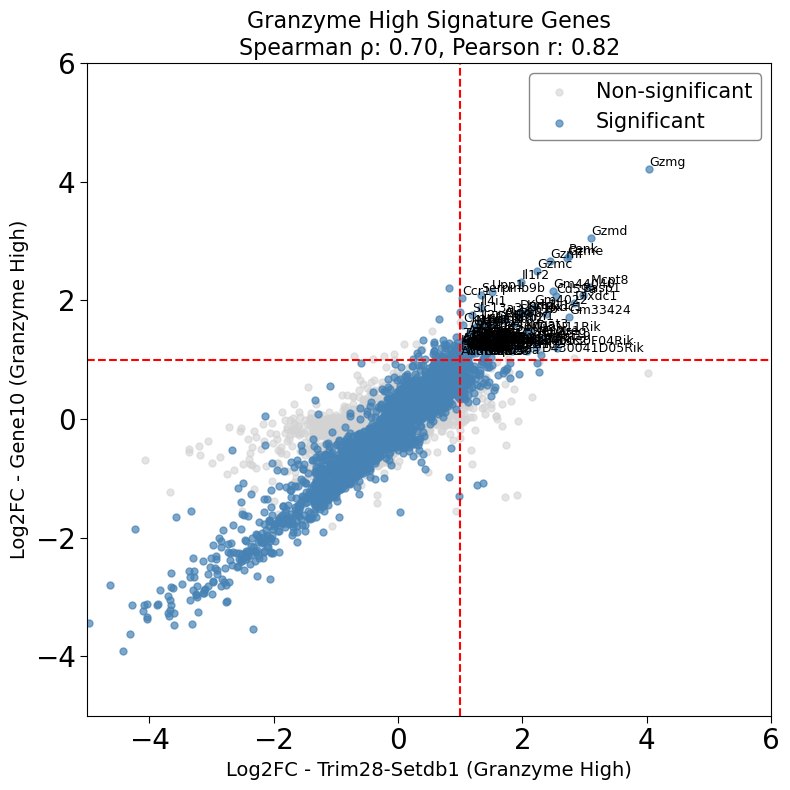

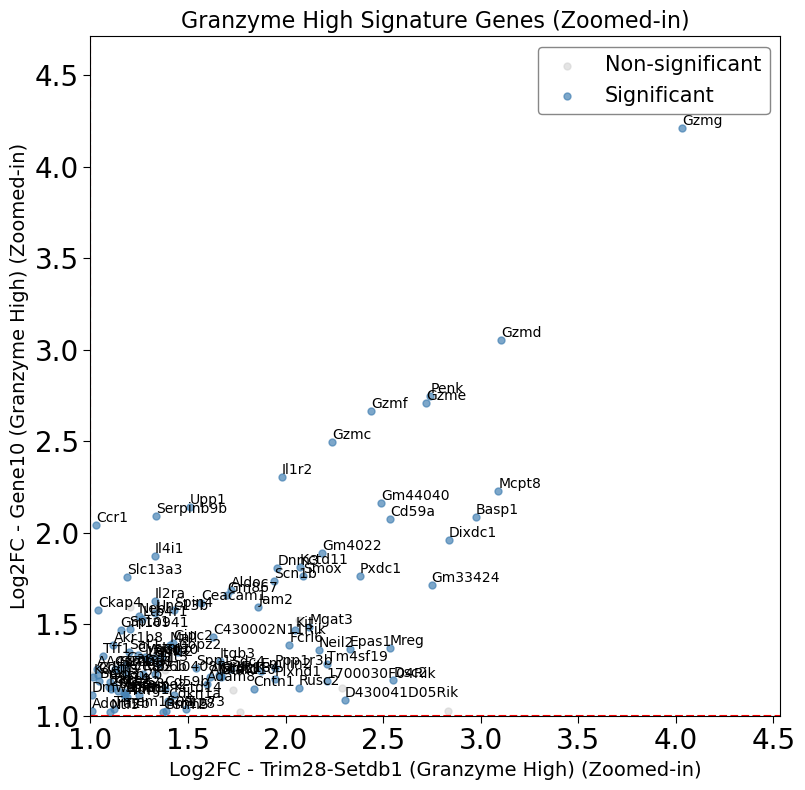

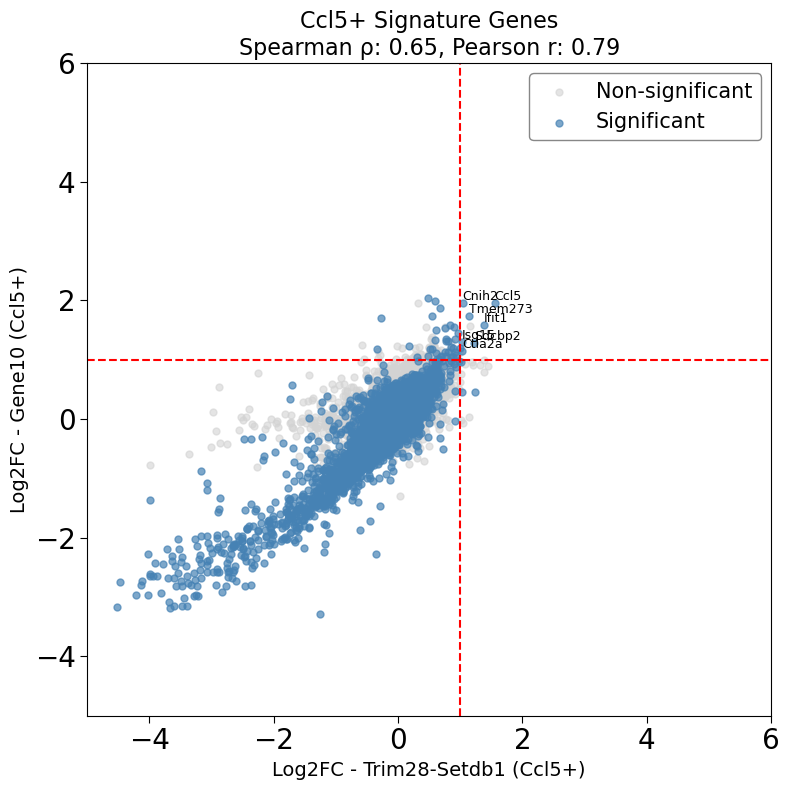

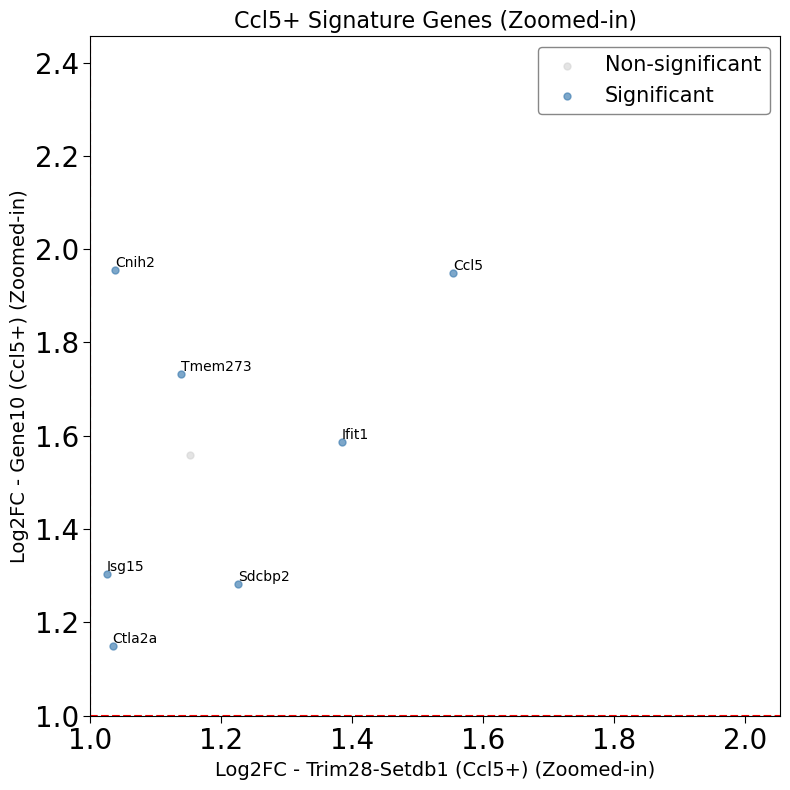

In [130]:
# Granzyme High scatterplot:
scatterplot_with_labels(
    df_x=gh_trim28_setdb1,
    df_y=gh_gene10,
    xlabel='Log2FC - Trim28-Setdb1 (Granzyme High)',
    ylabel='Log2FC - Gene10 (Granzyme High)',
    title='Granzyme High Signature Genes',
    logFC_thresh=1.0
)

# Ccl5+ scatterplot:
scatterplot_with_labels(
    df_x=ccl5_trim28_setdb1,
    df_y=ccl5_gene10,
    xlabel='Log2FC - Trim28-Setdb1 (Ccl5+)',
    ylabel='Log2FC - Gene10 (Ccl5+)',
    title='Ccl5+ Signature Genes',
    logFC_thresh=1.0
)

## above Ifit1, Isg15 are interfron-induced activation

In [156]:
trim28_setdb1_adata = get_adata('trim28_setdb1', use_cells_only_one_construct=False, remove_NG=False, get_raw_scaled=False)
gene10_adata = get_adata('gene_10', use_cells_only_one_construct=False, remove_NG=False, get_raw_scaled=False)

In [157]:
# Subset trim28_setdb1_adata to only Cycling cells
trim28_setdb1_adata_cycling = trim28_setdb1_adata[trim28_setdb1_adata.obs['cell_type'] == 'Cycling'].copy()

# Subset gene10_adata to only Cycling cells
gene10_adata_cycling = gene10_adata[gene10_adata.obs['cell_type'] == 'Cycling'].copy()

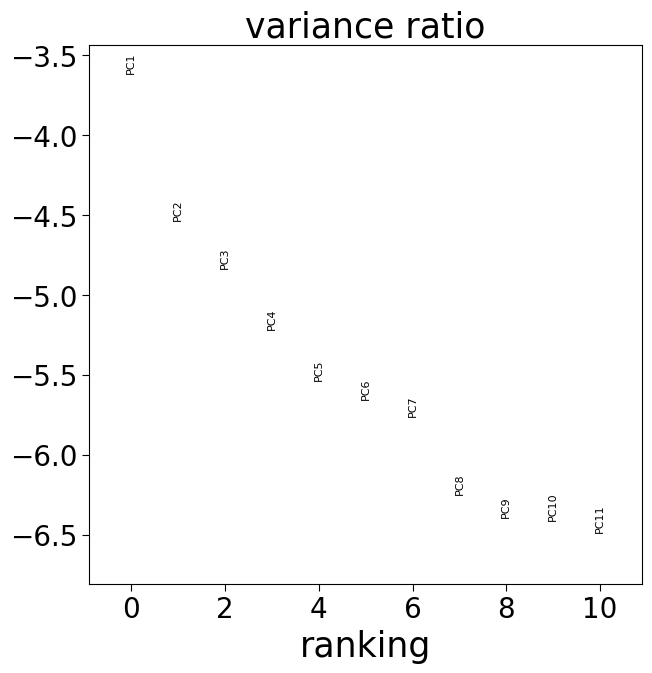

/Genomics/pritykinlab/dillon/software/miniconda/envs/envs/scvi3/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Genomics/pritykinlab/dillon/software/miniconda/envs/envs/scvi3/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/Genomics/pritykinlab/dillon/software/miniconda/envs/envs/scvi3/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


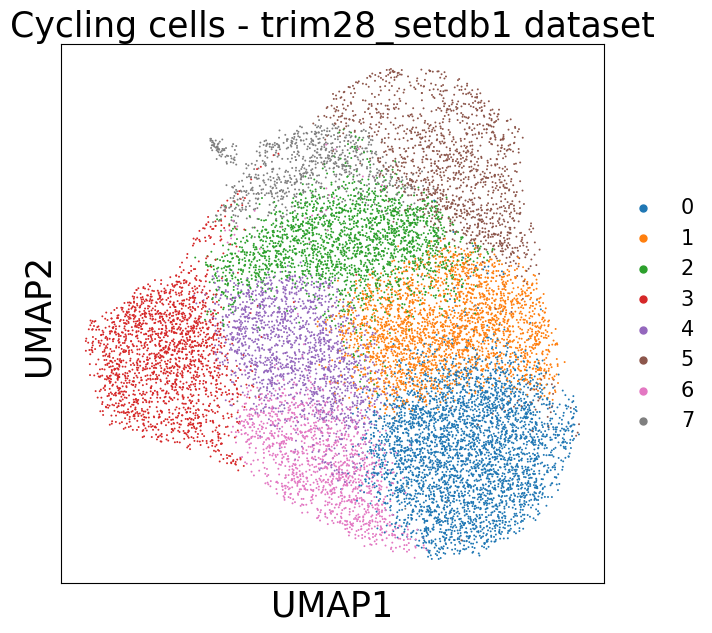

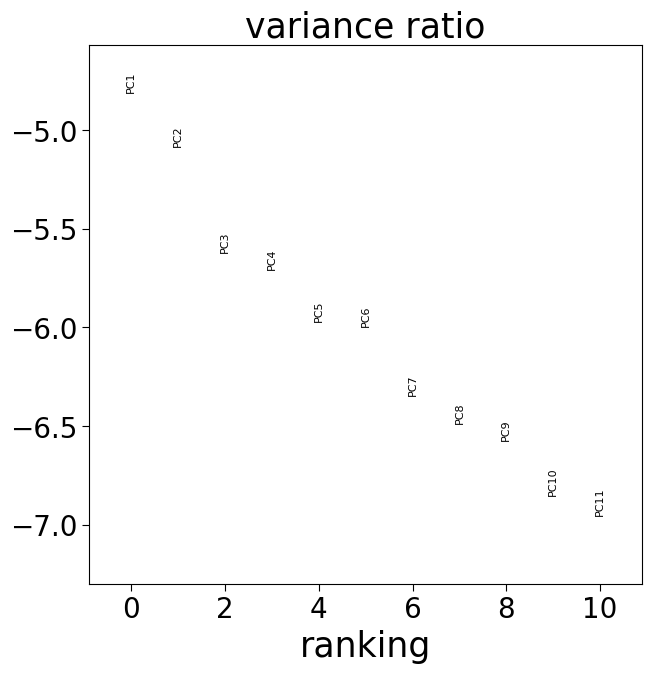

/Genomics/pritykinlab/dillon/software/miniconda/envs/envs/scvi3/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/Genomics/pritykinlab/dillon/software/miniconda/envs/envs/scvi3/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


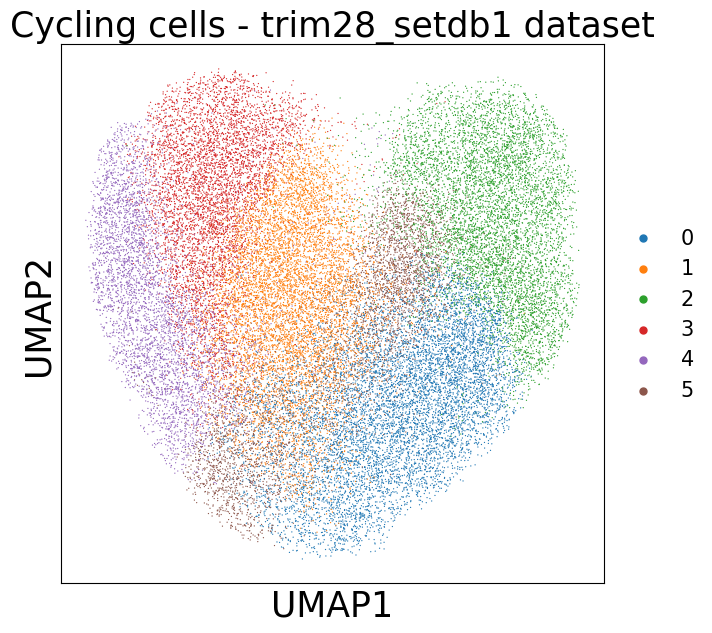

In [176]:
def pipeline(adata):
    adata = adata.raw.to_adata()
    sc.pp.filter_genes(adata, min_cells=10)
    adata.layers['raw'] = adata.X.copy()
    sc.pp.normalize_total(adata, exclude_highly_expressed=True)
    adata.layers['norm'] = adata.X.copy()
    sc.pp.log1p(adata)
    adata.layers['norm_log'] = adata.X.copy()
    sc.pp.scale(adata, max_value=10)
    adata.layers['norm_log_zscore'] = adata.X.copy()
    sc.tl.pca(adata, svd_solver='arpack', n_comps=100)
    sc.pl.pca_variance_ratio(adata, n_pcs=10, log=True)
    # Neighborhood graph
    sc.pp.neighbors(adata, n_neighbors=15, n_pcs=10)

    # UMAP embedding
    sc.tl.umap(adata)

    # Leiden clustering
    sc.tl.leiden(adata, resolution=0.5)

    # Visualize clearly
    sc.pl.umap(adata, color=['leiden'], title='Cycling cells - trim28_setdb1 dataset')
    return adata
    
trim28_setdb1_adata_cycling = pipeline(trim28_setdb1_adata_cycling)
gene10_adata_cycling = pipeline(gene10_adata_cycling)

/tmp/ipykernel_2760416/3580382618.py:25: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cluster_medians = adata.obs.groupby(cluster_key)[score_key].median().sort_values(ascending=False)


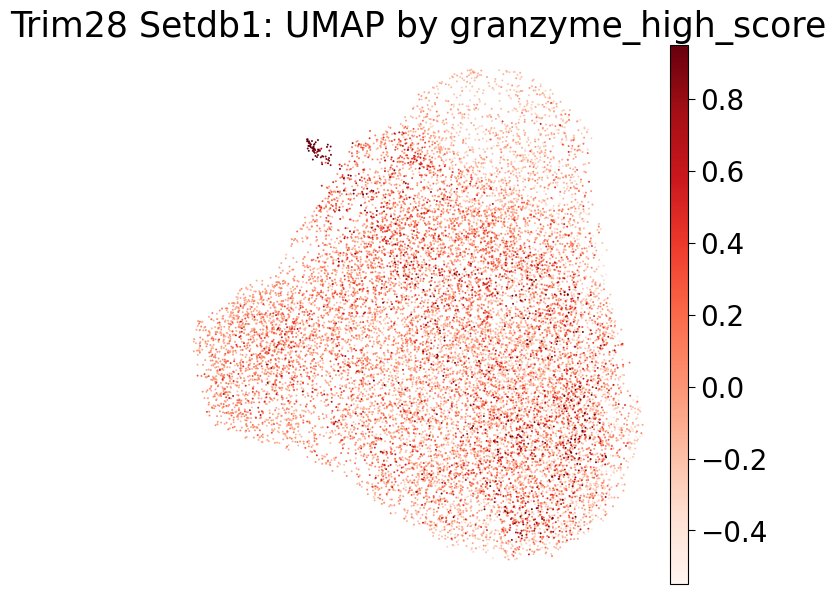

/Genomics/pritykinlab/dillon/software/miniconda/envs/envs/scvi3/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/Genomics/pritykinlab/dillon/software/miniconda/envs/envs/scvi3/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


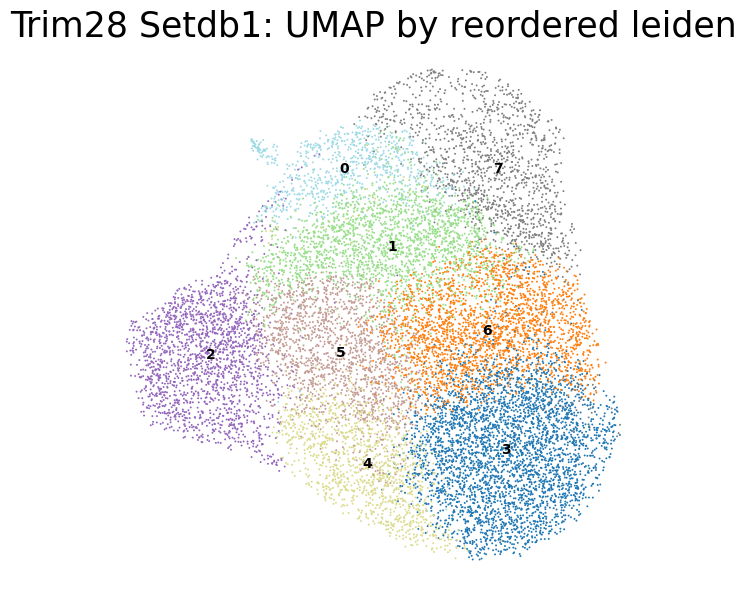

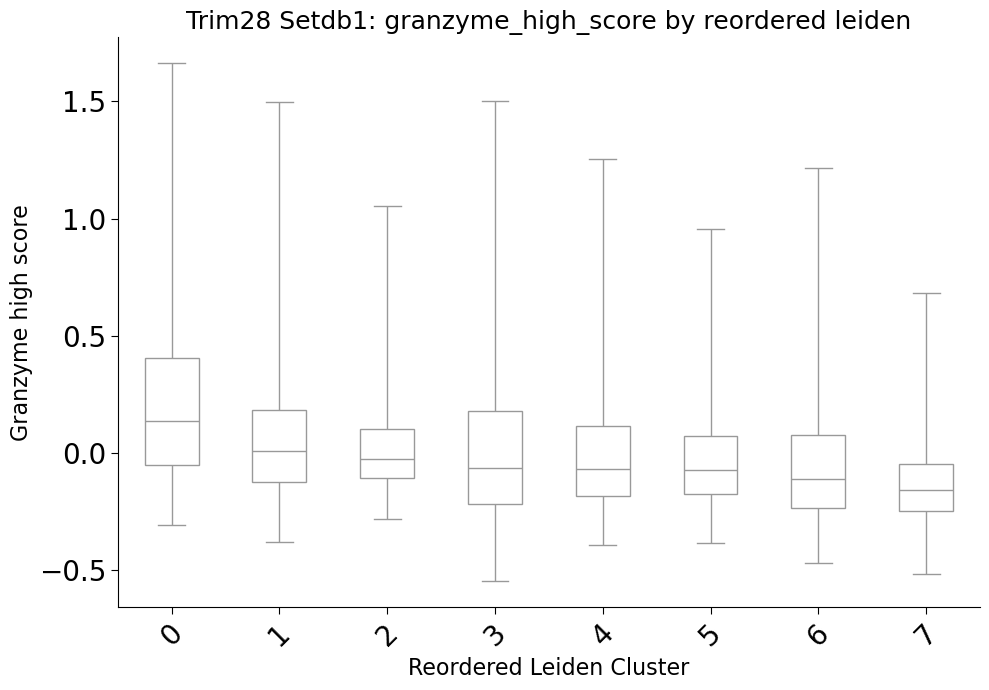

/Genomics/pritykinlab/dillon/software/miniconda/envs/envs/scvi3/lib/python3.11/site-packages/scanpy/plotting/_dotplot.py:168: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  obs_bool.groupby(level=0).sum() / obs_bool.groupby(level=0).count()
/Genomics/pritykinlab/dillon/software/miniconda/envs/envs/scvi3/lib/python3.11/site-packages/scanpy/plotting/_dotplot.py:178: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  dot_color_df = self.obs_tidy.groupby(level=0).mean()
/Genomics/pritykinlab/dillon/software/miniconda/envs/envs/scvi3/lib/python3.11/site-packages/scanpy/plotting/_dotplot.py:747: UserWarning: No data for 

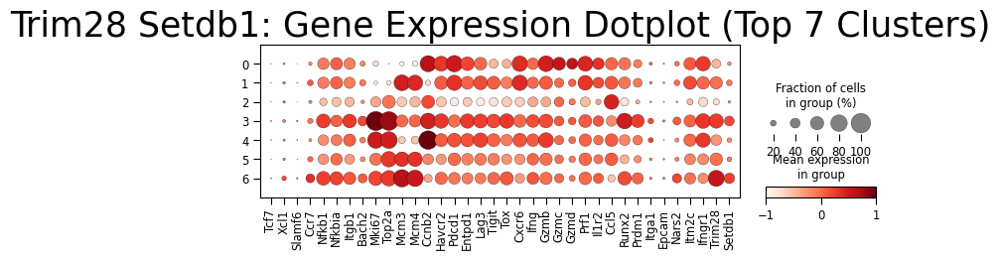

/tmp/ipykernel_2760416/3580382618.py:25: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cluster_medians = adata.obs.groupby(cluster_key)[score_key].median().sort_values(ascending=False)


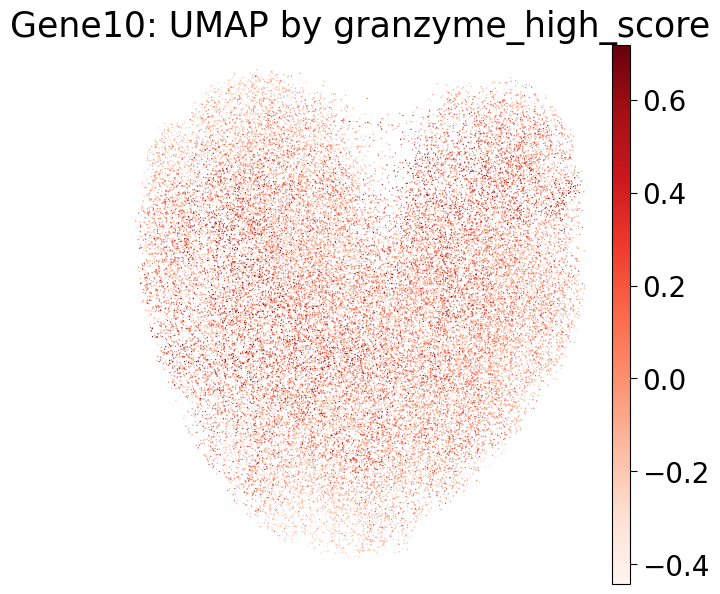

/Genomics/pritykinlab/dillon/software/miniconda/envs/envs/scvi3/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/Genomics/pritykinlab/dillon/software/miniconda/envs/envs/scvi3/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


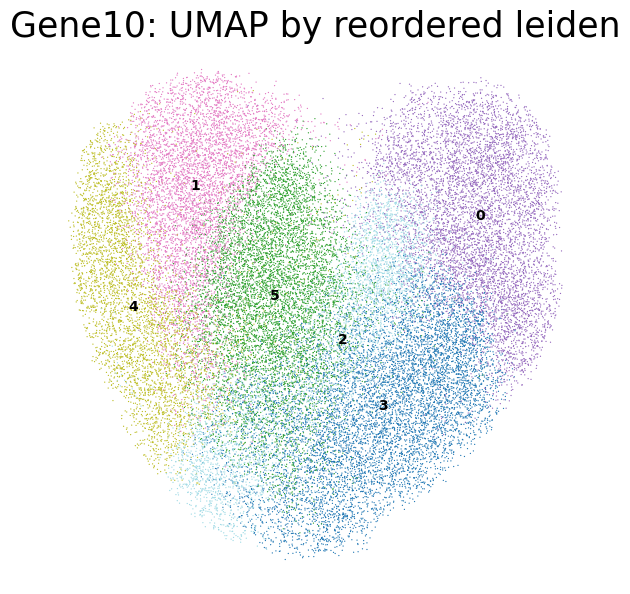

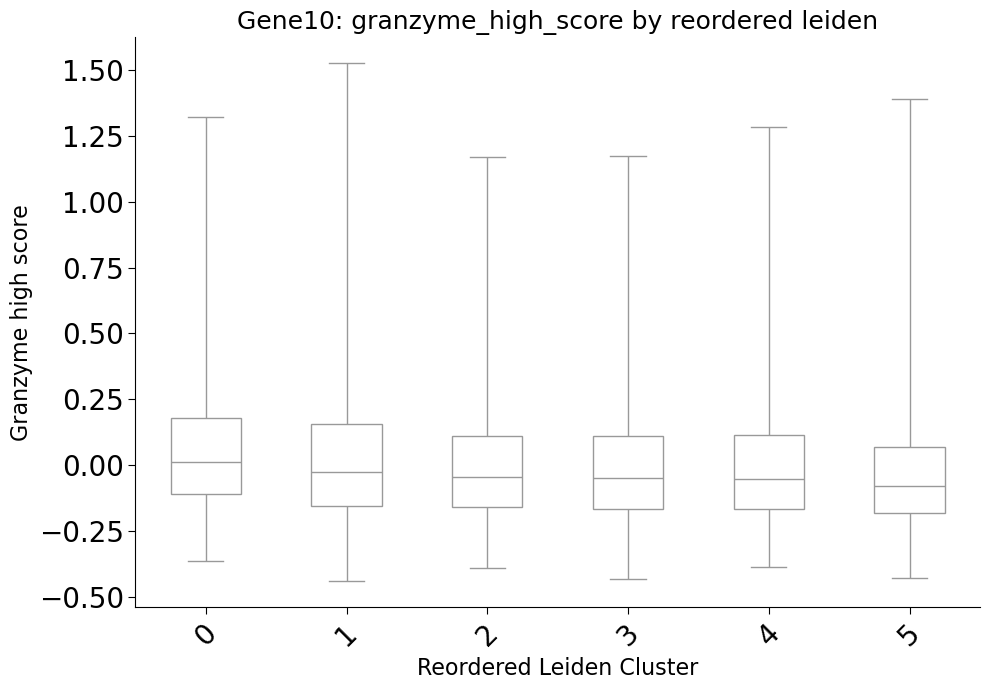

/Genomics/pritykinlab/dillon/software/miniconda/envs/envs/scvi3/lib/python3.11/site-packages/scanpy/plotting/_dotplot.py:168: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  obs_bool.groupby(level=0).sum() / obs_bool.groupby(level=0).count()
/Genomics/pritykinlab/dillon/software/miniconda/envs/envs/scvi3/lib/python3.11/site-packages/scanpy/plotting/_dotplot.py:178: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  dot_color_df = self.obs_tidy.groupby(level=0).mean()
/Genomics/pritykinlab/dillon/software/miniconda/envs/envs/scvi3/lib/python3.11/site-packages/scanpy/plotting/_dotplot.py:747: UserWarning: No data for 

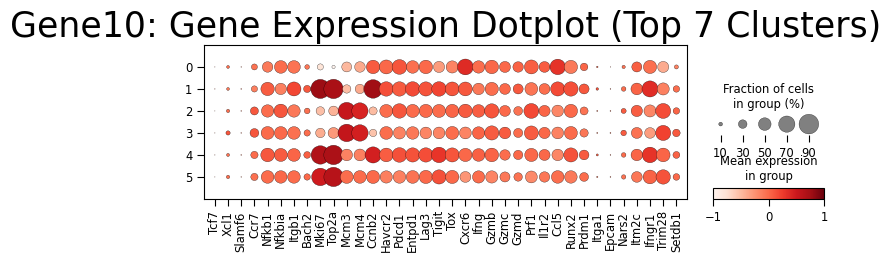

In [177]:
comprehensive_activation_plot(
    trim28_setdb1_adata_cycling,
    dataset_name='Trim28 Setdb1',
    dotplot_genes=dotplot_genes,
    signature_genes=gh_signature_genes,
    score_key='granzyme_high_score'
)

comprehensive_activation_plot(
    gene10_adata_cycling,
    dataset_name='Gene10',
    dotplot_genes=dotplot_genes,
    signature_genes=gh_signature_genes,
    score_key='granzyme_high_score'
)

/tmp/ipykernel_2760416/3580382618.py:25: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cluster_medians = adata.obs.groupby(cluster_key)[score_key].median().sort_values(ascending=False)


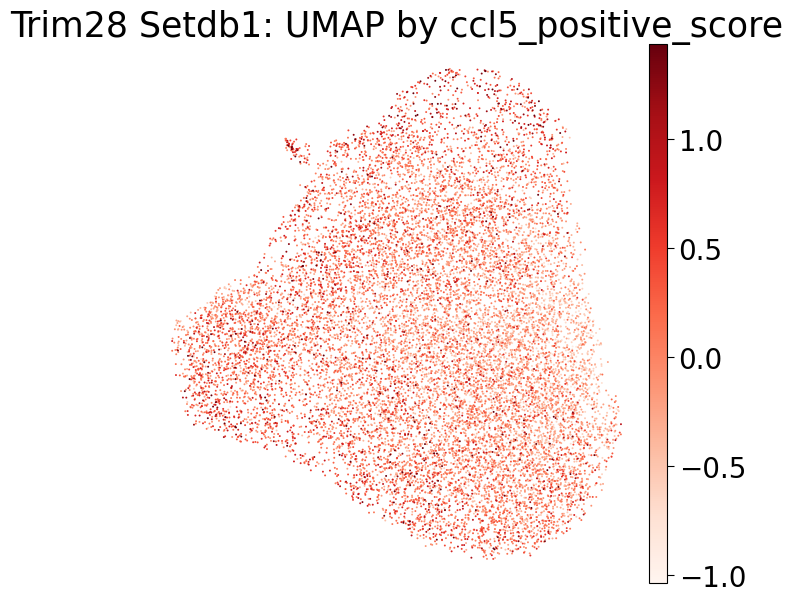

/Genomics/pritykinlab/dillon/software/miniconda/envs/envs/scvi3/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/Genomics/pritykinlab/dillon/software/miniconda/envs/envs/scvi3/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


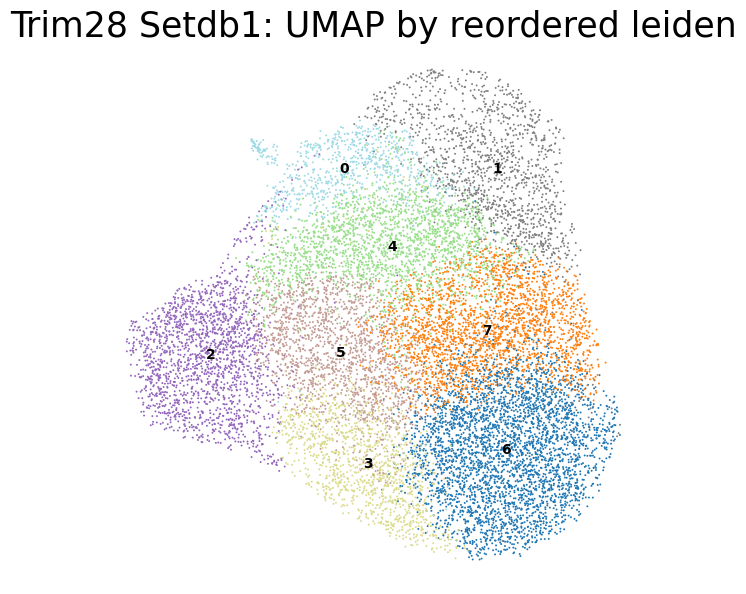

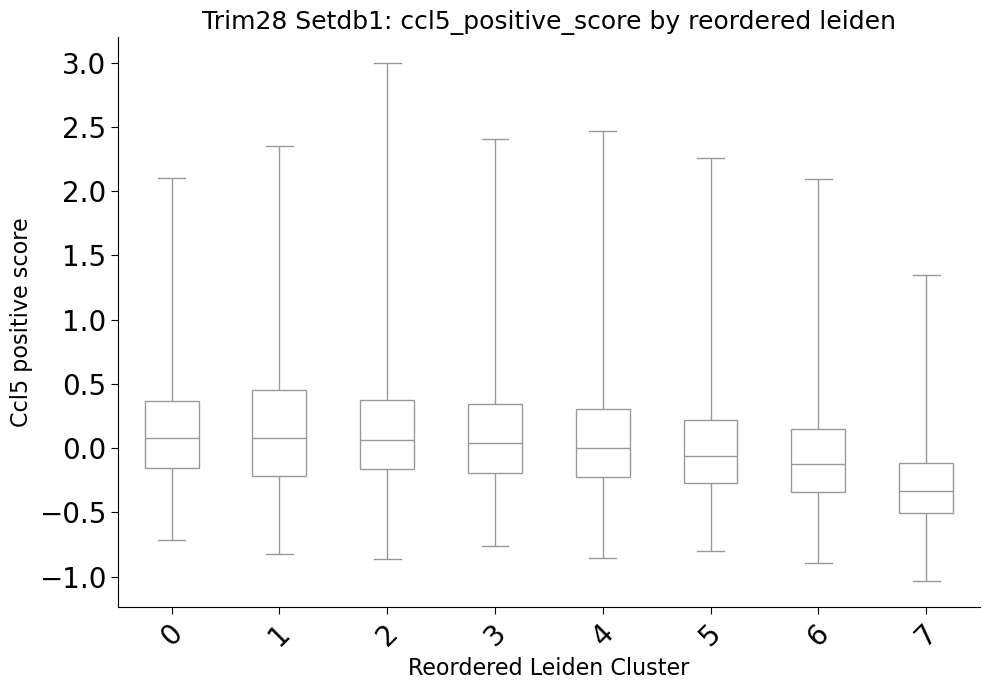

/Genomics/pritykinlab/dillon/software/miniconda/envs/envs/scvi3/lib/python3.11/site-packages/scanpy/plotting/_dotplot.py:168: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  obs_bool.groupby(level=0).sum() / obs_bool.groupby(level=0).count()
/Genomics/pritykinlab/dillon/software/miniconda/envs/envs/scvi3/lib/python3.11/site-packages/scanpy/plotting/_dotplot.py:178: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  dot_color_df = self.obs_tidy.groupby(level=0).mean()
/Genomics/pritykinlab/dillon/software/miniconda/envs/envs/scvi3/lib/python3.11/site-packages/scanpy/plotting/_dotplot.py:747: UserWarning: No data for 

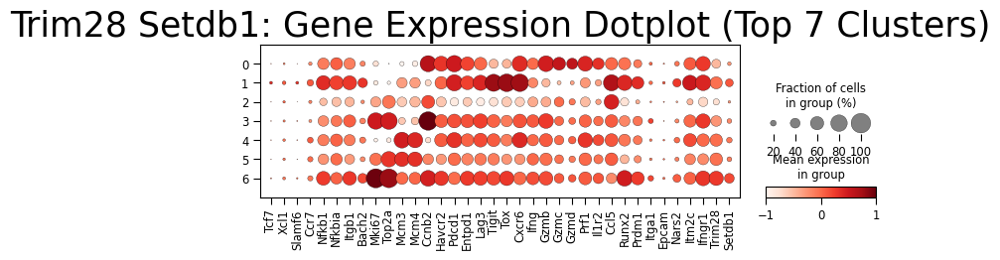

/tmp/ipykernel_2760416/3580382618.py:25: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cluster_medians = adata.obs.groupby(cluster_key)[score_key].median().sort_values(ascending=False)


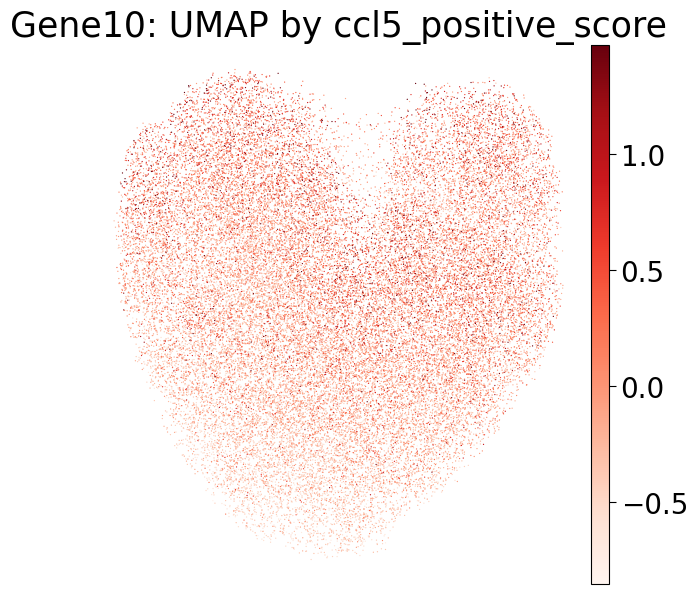

/Genomics/pritykinlab/dillon/software/miniconda/envs/envs/scvi3/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/Genomics/pritykinlab/dillon/software/miniconda/envs/envs/scvi3/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


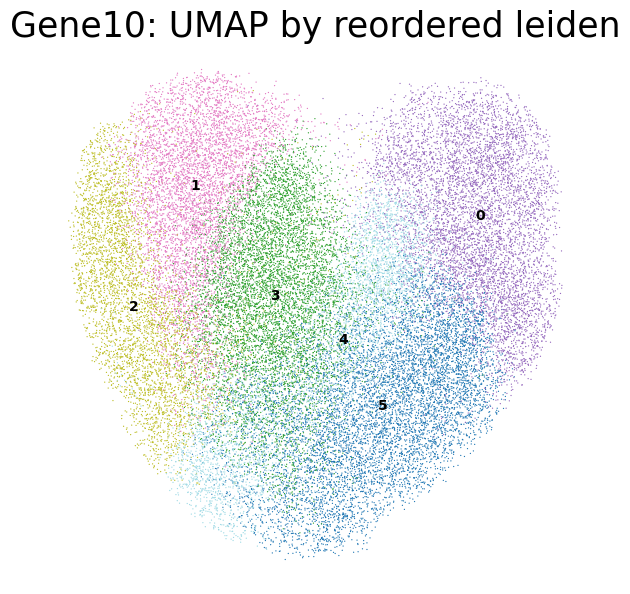

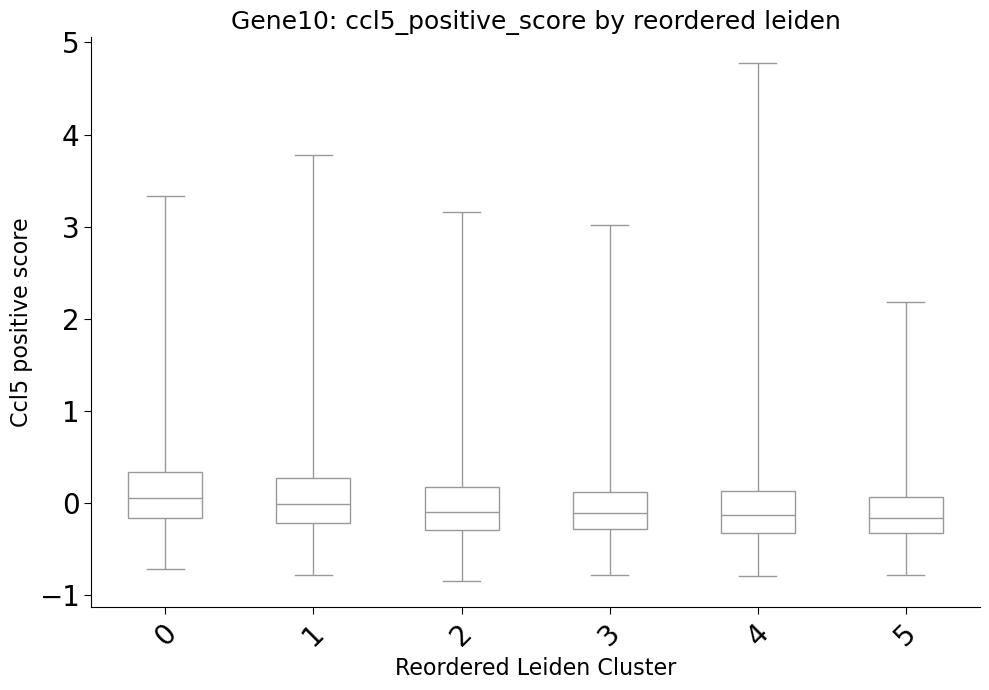

/Genomics/pritykinlab/dillon/software/miniconda/envs/envs/scvi3/lib/python3.11/site-packages/scanpy/plotting/_dotplot.py:168: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  obs_bool.groupby(level=0).sum() / obs_bool.groupby(level=0).count()
/Genomics/pritykinlab/dillon/software/miniconda/envs/envs/scvi3/lib/python3.11/site-packages/scanpy/plotting/_dotplot.py:178: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  dot_color_df = self.obs_tidy.groupby(level=0).mean()
/Genomics/pritykinlab/dillon/software/miniconda/envs/envs/scvi3/lib/python3.11/site-packages/scanpy/plotting/_dotplot.py:747: UserWarning: No data for 

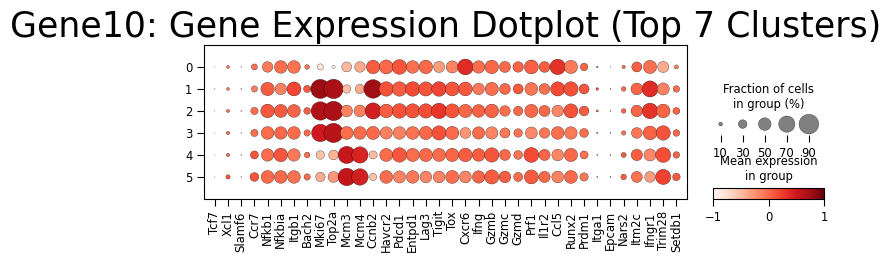

In [178]:
comprehensive_activation_plot(
    trim28_setdb1_adata_cycling,
    dataset_name='Trim28 Setdb1',
    dotplot_genes=dotplot_genes,
    signature_genes=ccl5_signature_genes,
    score_key='ccl5_positive_score'
)

comprehensive_activation_plot(
    gene10_adata_cycling,
    dataset_name='Gene10',
    dotplot_genes=dotplot_genes,
    signature_genes=ccl5_signature_genes,
    score_key='ccl5_positive_score'
)